In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("/content/diabetes.csv")

In [3]:
print("shape:",df.shape)

shape: (768, 9)


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [8]:
df.duplicated().sum()

np.int64(0)

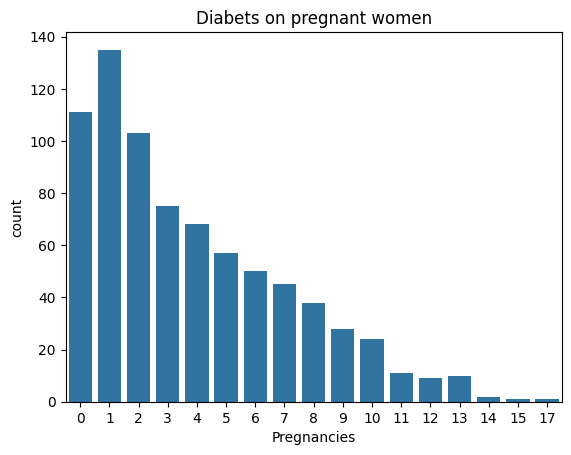

In [9]:
sns.countplot(data=df,x="Pregnancies")
plt.title("Diabets on pregnant women")
plt.show()

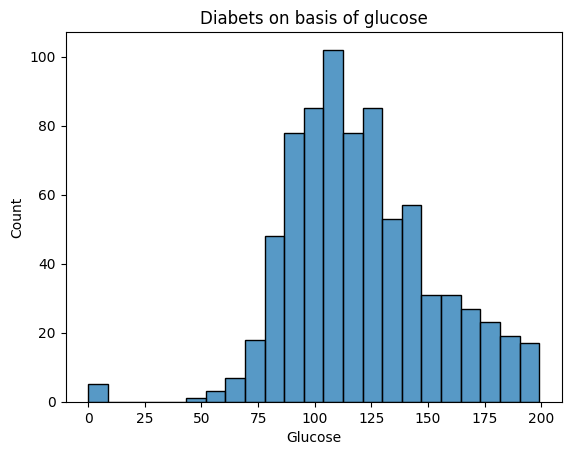

In [10]:
sns.histplot(data=df,x="Glucose")
plt.title("Diabets on basis of glucose")
plt.show()

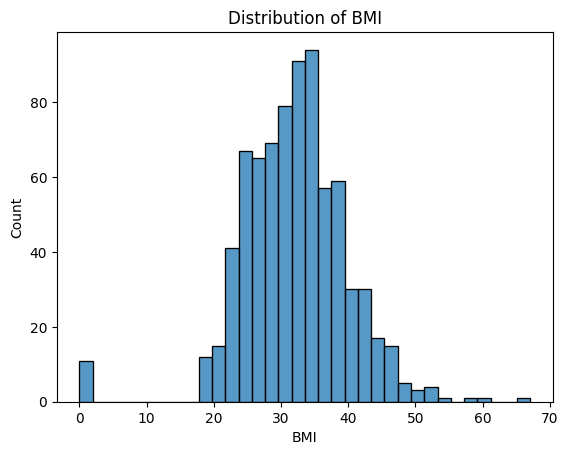

In [11]:
sns.histplot(data=df,x="BMI")
plt.title("Distribution of BMI")
plt.show()

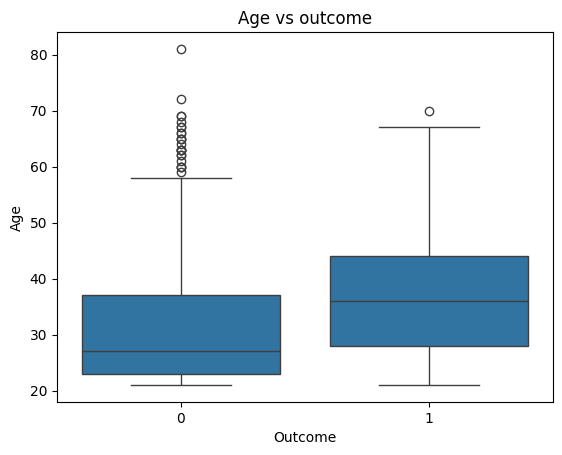

In [12]:
sns.boxplot(data = df, x = "Outcome", y = "Age")
plt.title("Age vs outcome")
plt.show()

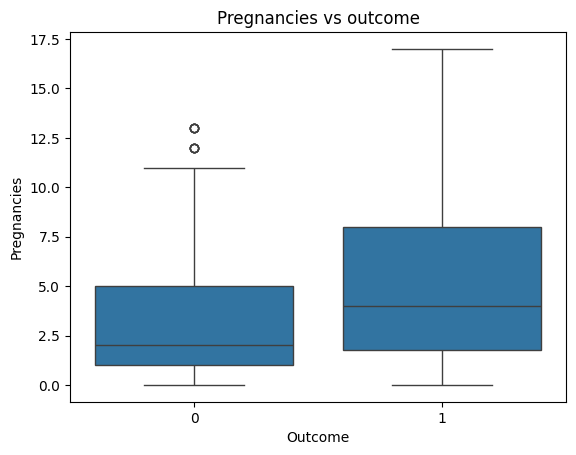

In [13]:
sns.boxplot(data=df,x="Outcome",y="Pregnancies")
plt.title("Pregnancies vs outcome")
plt.show()

In [14]:
numeric_df = df.select_dtypes(include = ["int64","float64"]).columns

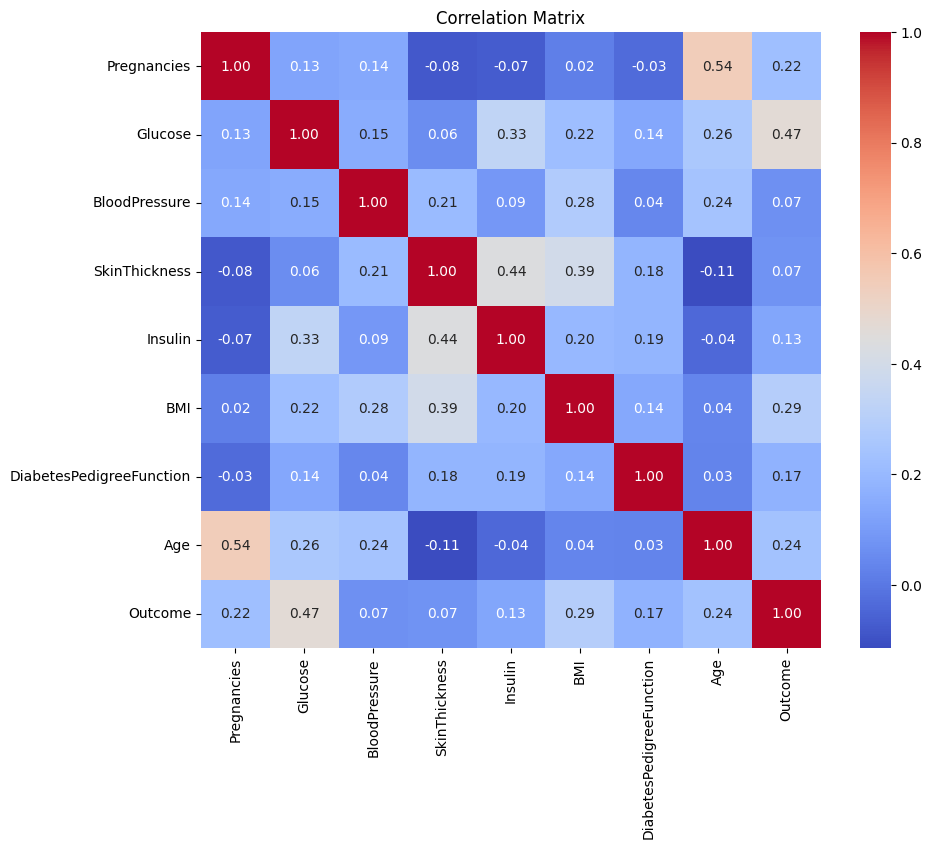

In [15]:
# Multivariate Analysis
plt.figure(figsize = (10, 8))
sns.heatmap(df[numeric_df].corr(), annot = True, cmap = "coolwarm",fmt= ".2f")
plt.title("Correlation Matrix")
plt.show()

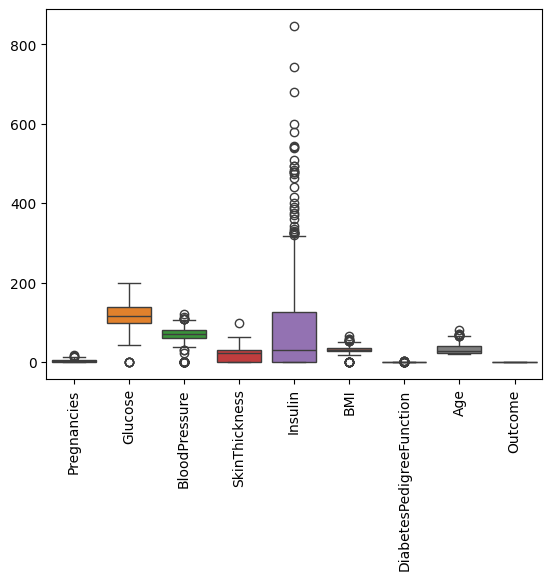

In [16]:
# Outlier detection
sns.boxplot(data =df[numeric_df])
plt.xticks(rotation = 90)
plt.show()

In [17]:
numerical_columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]

In [18]:
for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(column, ":", len(outliers), "outliers")

Pregnancies : 4 outliers
Glucose : 5 outliers
BloodPressure : 45 outliers
SkinThickness : 1 outliers
Insulin : 34 outliers
BMI : 19 outliers
DiabetesPedigreeFunction : 29 outliers
Age : 9 outliers


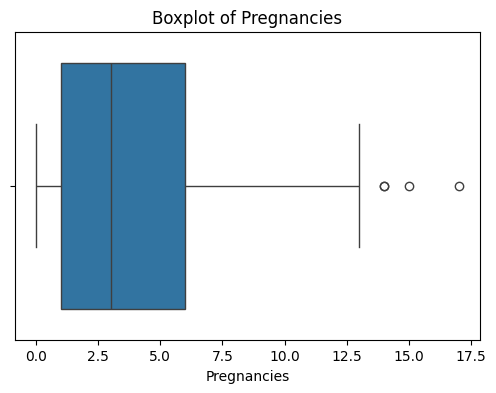

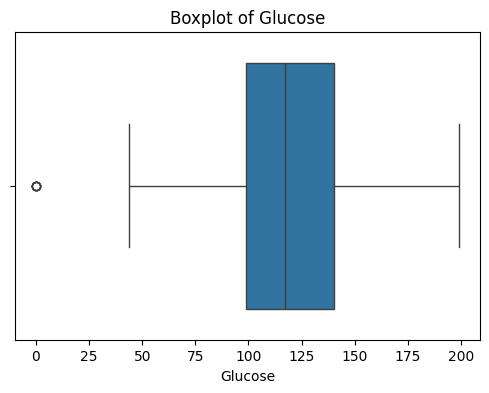

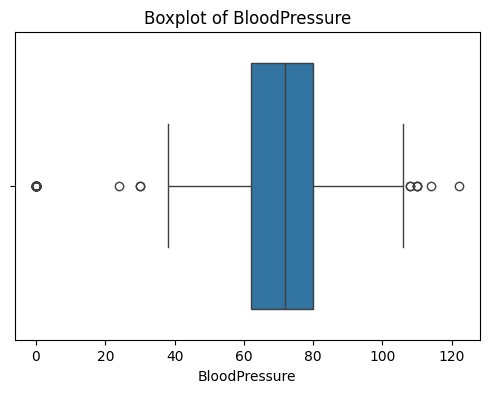

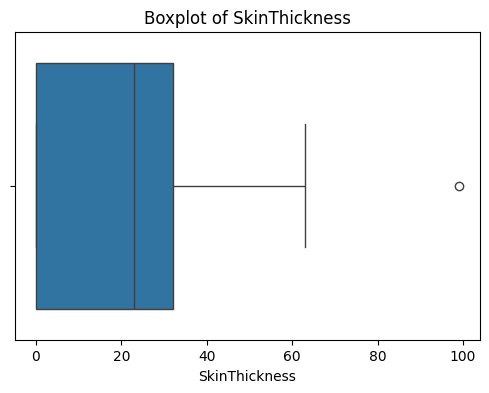

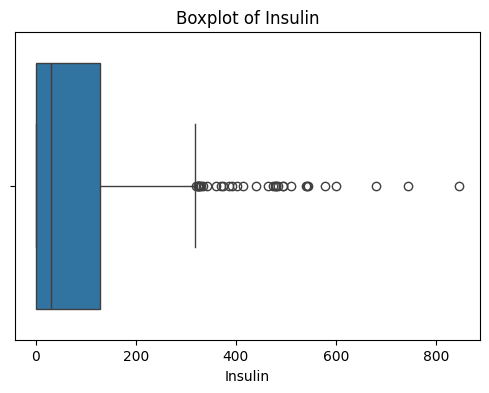

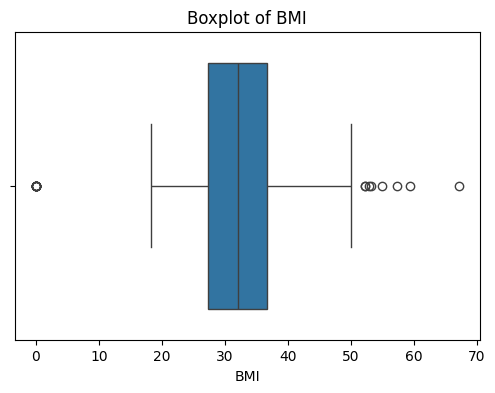

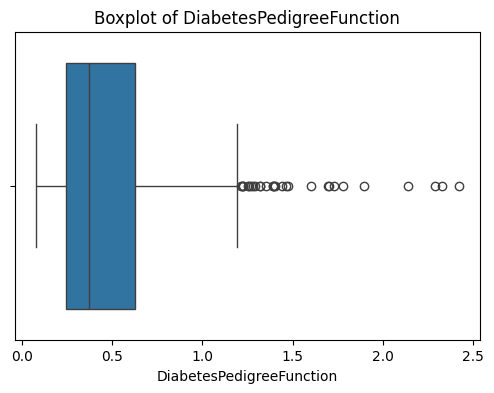

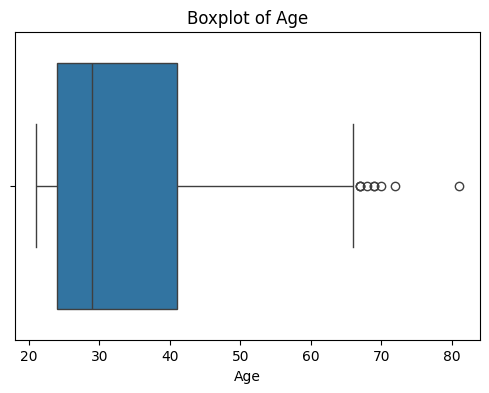

In [19]:
for column in numerical_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')
    plt.show()

In [20]:
x=  df.drop("Outcome", axis = 1)
y= df["Outcome"]

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [22]:
print(x_train.shape, x_test.shape,y_train.shape, y_test.shape)

(614, 8) (154, 8) (614,) (154,)


In [23]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
x_train_imputed = imputer.fit_transform(x_train)
x_test_imputed = imputer.transform(x_test)

In [24]:
from imblearn.over_sampling import SMOTE
print("Before Smote:\n",y_train.value_counts())
smote = SMOTE(random_state = 42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)
print("After Smote:\n",y_train_resampled.value_counts())

Before Smote:
 Outcome
0    401
1    213
Name: count, dtype: int64
After Smote:
 Outcome
0    401
1    401
Name: count, dtype: int64


In [25]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_imputed)
x_test_scaled = scaler.transform(x_test_imputed)

In [26]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x_train_scaled, y_train)


LogisticRegression()

In [27]:
y_pred = model.predict(x_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [28]:
from sklearn.metrics import roc_auc_score
y_prob = model.predict_proba(x_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8146923783287419


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


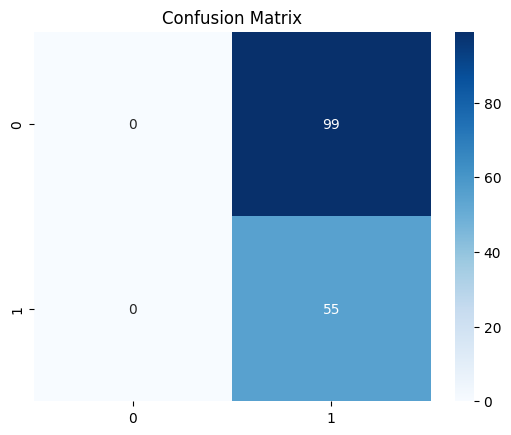

accuracy: 0.35714285714285715
precision: 0.35714285714285715
recall: 1.0
f1 score: 0.5263157894736842
classification report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        99
           1       0.36      1.00      0.53        55

    accuracy                           0.36       154
   macro avg       0.18      0.50      0.26       154
weighted avg       0.13      0.36      0.19       154



In [29]:
# Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
sns.heatmap(conf_matrix, annot = True, fmt = "d", cmap = "Blues")
plt.title("Confusion Matrix")
plt.show()
print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("f1 score:", f1)
print("classification report:\n", class_report)